In [4]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error
)

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

FINAL_DIR = PROJECT_ROOT / "data" / "final"
TABLES_DIR = PROJECT_ROOT / "tables"
FIGURES_DIR = PROJECT_ROOT / "figures"

TABLES_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)

Project root: C:\Users\ibrah\RPDA8412 Research Project


In [5]:
df = pd.read_csv(
    FINAL_DIR / "model_features_20d_provisional.csv",
    parse_dates=["Date"]
)

df = (
    df.sort_values("Date")
      .reset_index(drop=True)
)

print("Dataset shape:", df.shape)

print(
    "Date range:",
    df["Date"].min(),
    "to",
    df["Date"].max()
)

display(df.head())

Dataset shape: (3944, 17)
Date range: 2010-03-31 00:00:00 to 2025-12-02 00:00:00


,Date,Return_Lag1,Absolute_Return,RV_Historical_5D,RV_Historical_10D,RV_Historical_20D,RV_Historical_60D,RV_20D_Lag1,GPR_Level,GPR_Change,GPR_MA5,GPR_MA20,EPU_Level,EPU_Change,EPU_MA5,EPU_MA20,RV_Future_20D
0,2010-03-31,0.000043,0.003278,0.006806,0.013404,0.022818,0.069107,0.022585,137.876358,76.983566,70.173136,74.291204,63.15,-28.16,101.636,106.6910,0.039093
1,2010-04-01,-0.003278,0.007386,0.009898,0.015301,0.023692,0.069431,0.022818,66.391121,-71.485237,71.006355,74.425599,89.89,26.74,94.942,108.0945,0.041899
2,2010-04-05,0.007386,0.007897,0.012641,0.016446,0.020741,0.069876,0.023692,94.452034,28.060913,79.149881,75.084698,160.56,70.67,109.252,111.3040,0.043164
3,2010-04-06,0.007897,0.001683,0.011424,0.015731,0.020808,0.069782,0.020741,91.553383,-2.898651,90.233138,76.860383,94.44,-66.12,99.870,109.0490,0.049421
4,2010-04-07,0.001683,0.005894,0.012854,0.015204,0.021559,0.069972,0.020808,112.219978,20.666595,100.498575,76.146670,58.02,-36.42,93.212,106.7380,0.049511


In [6]:
MARKET_FEATURES = [
    "Return_Lag1",
    "Absolute_Return",
    "RV_Historical_5D",
    "RV_Historical_10D",
    "RV_Historical_20D",
    "RV_Historical_60D",
    "RV_20D_Lag1"
]

TARGET = "RV_Future_20D"

HORIZON = 20

required_columns = (
    ["Date"] + MARKET_FEATURES + [TARGET]
)

assert df[required_columns].notna().all().all()

assert df["Date"].is_unique

assert df["Date"].is_monotonic_increasing

print("Feature checks passed!")
print("Number of predictors:", len(MARKET_FEATURES))
print("Forecast horizon:", HORIZON, "trading days")

Feature checks passed!
Number of predictors: 7
Forecast horizon: 20 trading days


In [7]:
VALIDATION_START = pd.Timestamp("2020-01-01")
VALIDATION_END = pd.Timestamp("2022-12-31")

validation_indices = df.index[
    (df["Date"] >= VALIDATION_START) &
    (df["Date"] <= VALIDATION_END)
].to_numpy()

print(
    "Validation observations:",
    len(validation_indices)
)

print(
    "First validation date:",
    df.loc[validation_indices[0], "Date"]
)

print(
    "Last validation date:",
    df.loc[validation_indices[-1], "Date"]
)

assert len(validation_indices) == 756

print("Validation split verified!")

Validation observations: 756
First validation date: 2020-01-02 00:00:00
Last validation date: 2022-12-30 00:00:00
Validation split verified!


In [8]:
def expanding_window_linear_regression(
    data,
    features,
    target,
    forecast_indices,
    horizon=20
):
    results = []

    for forecast_idx in forecast_indices:

        # Latest training row whose future target
        # is fully observed by the forecast origin.
        last_train_idx = forecast_idx - horizon

        if last_train_idx < 0:
            raise ValueError(
                "Insufficient history for this forecast."
            )

        train_data = data.iloc[:last_train_idx + 1]

        forecast_data = data.iloc[
            [forecast_idx]
        ]

        X_train = train_data[features]
        y_train = train_data[target]

        X_forecast = forecast_data[features]

        model = LinearRegression()

        model.fit(
            X_train,
            y_train
        )

        prediction = model.predict(
            X_forecast
        )[0]

        # Realised volatility cannot be negative.
        prediction = max(0.0, prediction)

        results.append({
            "Date": data.loc[
                forecast_idx, "Date"
            ],

            "Actual": data.loc[
                forecast_idx, target
            ],

            "Predicted": prediction,

            "Training_Observations": len(
                train_data
            ),

            "Last_Training_Date": data.loc[
                last_train_idx, "Date"
            ]
        })

    return pd.DataFrame(results)

In [9]:
walk_forward_lr = expanding_window_linear_regression(
    data=df,
    features=MARKET_FEATURES,
    target=TARGET,
    forecast_indices=validation_indices,
    horizon=HORIZON
)

print(
    "Forecasts generated:",
    len(walk_forward_lr)
)

display(walk_forward_lr.head())

display(walk_forward_lr.tail())

Forecasts generated: 756


,Date,Actual,Predicted,Training_Observations,Last_Training_Date
0,2020-01-02,0.032513,0.028484,2437,2019-12-03
1,2020-01-03,0.032545,0.027550,2438,2019-12-04
2,2020-01-06,0.035606,0.030688,2439,2019-12-05
3,2020-01-07,0.037217,0.027702,2440,2019-12-06
4,2020-01-08,0.037043,0.029378,2441,2019-12-09


,Date,Actual,Predicted,Training_Observations,Last_Training_Date
751,2022-12-23,0.047205,0.053542,3188,2022-11-25
752,2022-12-27,0.048288,0.046596,3189,2022-11-28
753,2022-12-28,0.046815,0.052944,3190,2022-11-29
754,2022-12-29,0.045414,0.055006,3191,2022-11-30
755,2022-12-30,0.047615,0.043302,3192,2022-12-01


In [10]:
assert len(walk_forward_lr) == 756

assert walk_forward_lr["Date"].is_unique

assert walk_forward_lr["Predicted"].notna().all()

assert (
    walk_forward_lr["Predicted"] >= 0
).all()

assert (
    walk_forward_lr["Last_Training_Date"]
    <
    walk_forward_lr["Date"]
).all()

assert (
    walk_forward_lr["Training_Observations"]
    .diff()
    .dropna()
    >= 0
).all()

# Verify the exact 20-trading-day gap.
for forecast_idx, row in zip(
    validation_indices,
    walk_forward_lr.itertuples(index=False)
):
    expected_last_train_idx = (
        forecast_idx - HORIZON
    )

    expected_date = df.loc[
        expected_last_train_idx,
        "Date"
    ]

    assert (
        row.Last_Training_Date == expected_date
    )

print("All walk-forward checks passed!")

All walk-forward checks passed!


In [11]:
def evaluate_forecast(
    y_true,
    y_pred,
    epsilon=1e-4
):

    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    safe_mape = np.mean(
        np.abs(y_true - y_pred)
        /
        np.maximum(
            np.abs(y_true),
            epsilon
        )
    ) * 100

    return {
        "RMSE": rmse,
        "MAE": mae,
        "Safe_MAPE": safe_mape
    }

In [12]:
wf_lr_metrics = evaluate_forecast(
    walk_forward_lr["Actual"],
    walk_forward_lr["Predicted"]
)

print("=" * 60)
print("EXPANDING-WINDOW LINEAR REGRESSION")
print("=" * 60)

for metric, value in wf_lr_metrics.items():
    print(f"{metric}: {value:.6f}")

EXPANDING-WINDOW LINEAR REGRESSION
RMSE: 0.036248
MAE: 0.019111
Safe_MAPE: 28.795058


In [13]:
comparison = pd.DataFrame([
    {
        "Approach": "Fixed-Origin Linear Regression",
        "RMSE": 0.035895,
        "MAE": 0.018616,
        "Safe_MAPE": 27.730350
    },
    {
        "Approach": "Expanding-Window Linear Regression",
        **wf_lr_metrics
    }
])

display(
    comparison.round(6)
)

comparison.to_csv(
    TABLES_DIR /
    "linear_regression_walk_forward_comparison.csv",
    index=False
)

,Approach,RMSE,MAE,Safe_MAPE
0,Fixed-Origin Linear Regression,0.035895,0.018616,27.730350
1,Expanding-Window Linear Regression,0.036248,0.019111,28.795058


In [14]:
persistence_predictions = df.loc[
    validation_indices,
    "RV_Historical_20D"
].to_numpy()

persistence_metrics = evaluate_forecast(
    walk_forward_lr["Actual"],
    persistence_predictions
)

benchmark_comparison = pd.DataFrame([
    {
        "Model": "Walk-Forward Linear Regression",
        **wf_lr_metrics
    },
    {
        "Model": "Persistence",
        **persistence_metrics
    }
])

display(
    benchmark_comparison.round(6)
)

benchmark_comparison.to_csv(
    TABLES_DIR /
    "walk_forward_lr_vs_persistence.csv",
    index=False
)

,Model,RMSE,MAE,Safe_MAPE
0,Walk-Forward Linear Regression,0.036248,0.019111,28.795058
1,Persistence,0.043013,0.023945,37.751981


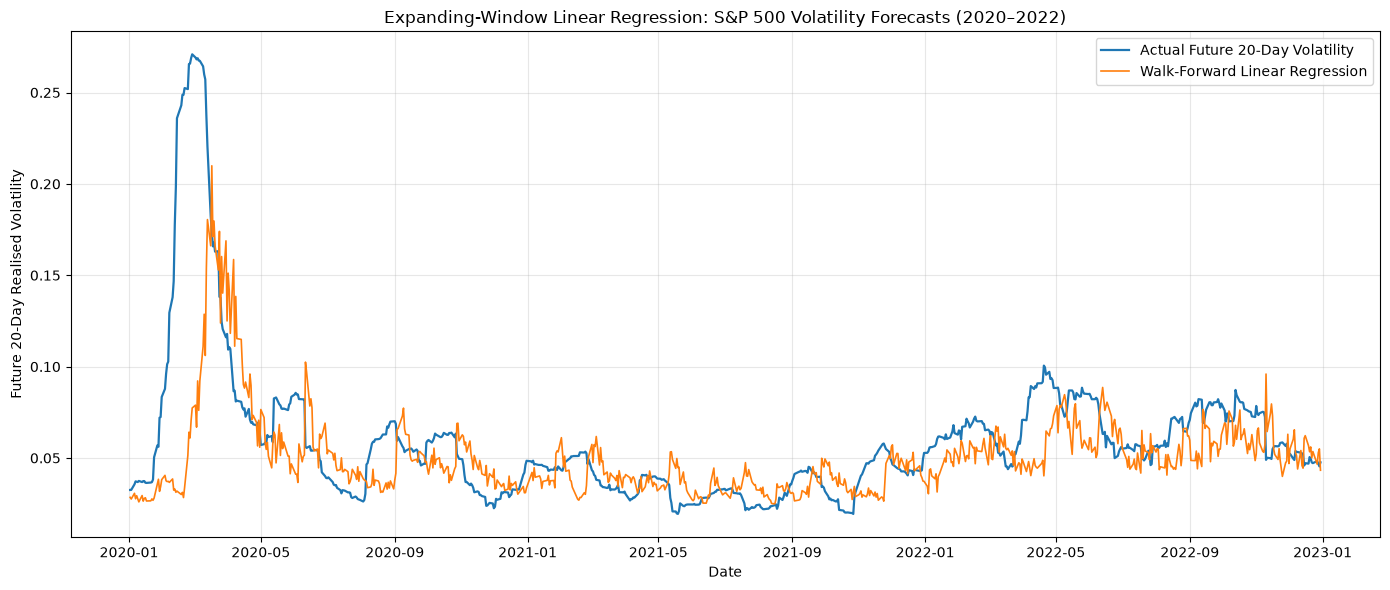

In [15]:
plt.figure(figsize=(14, 6))

plt.plot(
    walk_forward_lr["Date"],
    walk_forward_lr["Actual"],
    label="Actual Future 20-Day Volatility",
    linewidth=1.6
)

plt.plot(
    walk_forward_lr["Date"],
    walk_forward_lr["Predicted"],
    label="Walk-Forward Linear Regression",
    linewidth=1.2
)

plt.title(
    "Expanding-Window Linear Regression: "
    "S&P 500 Volatility Forecasts (2020–2022)"
)

plt.xlabel("Date")
plt.ylabel("Future 20-Day Realised Volatility")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR /
    "walk_forward_linear_regression.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [16]:
output_path = (
    TABLES_DIR /
    "walk_forward_linear_regression_predictions.csv"
)

walk_forward_lr.to_csv(
    output_path,
    index=False
)

print("Saved:", output_path)

print("\nTraining observations:")
print(
    "First forecast:",
    walk_forward_lr[
        "Training_Observations"
    ].iloc[0]
)

print(
    "Last forecast:",
    walk_forward_lr[
        "Training_Observations"
    ].iloc[-1]
)

Saved: C:\Users\ibrah\RPDA8412 Research Project\tables\walk_forward_linear_regression_predictions.csv

Training observations:
First forecast: 2437
Last forecast: 3192


In [17]:
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

print("Random Forest and XGBoost imported successfully!")

Random Forest and XGBoost imported successfully!


In [18]:
def expanding_window_tree_model(
    data,
    features,
    target,
    forecast_indices,
    model_type,
    horizon=20
):
    results = []

    for count, forecast_idx in enumerate(forecast_indices, start=1):

        last_train_idx = forecast_idx - horizon

        train_data = data.iloc[:last_train_idx + 1]
        forecast_data = data.iloc[[forecast_idx]]

        X_train = train_data[features]
        y_train = train_data[target]

        X_forecast = forecast_data[features]

        if model_type == "Random Forest":

            model = RandomForestRegressor(
                n_estimators=200,
                max_depth=8,
                min_samples_leaf=5,
                random_state=42,
                n_jobs=-1
            )

        elif model_type == "XGBoost":

            model = XGBRegressor(
                n_estimators=300,
                max_depth=3,
                learning_rate=0.03,
                subsample=0.8,
                colsample_bytree=0.8,
                objective="reg:squarederror",
                random_state=42,
                n_jobs=-1
            )

        else:
            raise ValueError("Unknown model type.")

        model.fit(X_train, y_train)

        prediction = float(
            model.predict(X_forecast)[0]
        )

        prediction = max(0.0, prediction)

        results.append({
            "Date": data.loc[forecast_idx, "Date"],
            "Actual": data.loc[forecast_idx, target],
            "Predicted": prediction,
            "Training_Observations": len(train_data),
            "Last_Training_Date": data.loc[
                last_train_idx, "Date"
            ]
        })

        if count % 25 == 0:
            print(
                f"{model_type}: "
                f"{count}/{len(forecast_indices)} forecasts completed"
            )

    return pd.DataFrame(results)

In [19]:
sample_indices = validation_indices[:10]

rf_sample = expanding_window_tree_model(
    data=df,
    features=MARKET_FEATURES,
    target=TARGET,
    forecast_indices=sample_indices,
    model_type="Random Forest",
    horizon=HORIZON
)

xgb_sample = expanding_window_tree_model(
    data=df,
    features=MARKET_FEATURES,
    target=TARGET,
    forecast_indices=sample_indices,
    model_type="XGBoost",
    horizon=HORIZON
)

print("\nRandom Forest sample:")
display(rf_sample)

print("\nXGBoost sample:")
display(xgb_sample)


Random Forest sample:


,Date,Actual,Predicted,Training_Observations,Last_Training_Date
0,2020-01-02,0.032513,0.019158,2437,2019-12-03
1,2020-01-03,0.032545,0.020833,2438,2019-12-04
2,2020-01-06,0.035606,0.025930,2439,2019-12-05
3,2020-01-07,0.037217,0.023343,2440,2019-12-06
4,2020-01-08,0.037043,0.023730,2441,2019-12-09
5,2020-01-09,0.036845,0.024330,2442,2019-12-10
6,2020-01-10,0.037452,0.026910,2443,2019-12-11
7,2020-01-13,0.036840,0.031498,2444,2019-12-12
8,2020-01-14,0.037368,0.027855,2445,2019-12-13
9,2020-01-15,0.037357,0.027112,2446,2019-12-16



XGBoost sample:


,Date,Actual,Predicted,Training_Observations,Last_Training_Date
0,2020-01-02,0.032513,0.026312,2437,2019-12-03
1,2020-01-03,0.032545,0.024793,2438,2019-12-04
2,2020-01-06,0.035606,0.028673,2439,2019-12-05
3,2020-01-07,0.037217,0.026528,2440,2019-12-06
4,2020-01-08,0.037043,0.026626,2441,2019-12-09
5,2020-01-09,0.036845,0.026338,2442,2019-12-10
6,2020-01-10,0.037452,0.026991,2443,2019-12-11
7,2020-01-13,0.036840,0.031415,2444,2019-12-12
8,2020-01-14,0.037368,0.027504,2445,2019-12-13
9,2020-01-15,0.037357,0.026667,2446,2019-12-16


In [20]:
for name, results in [
    ("Random Forest", rf_sample),
    ("XGBoost", xgb_sample)
]:
    assert len(results) == 10

    assert results["Predicted"].notna().all()

    assert (results["Predicted"] >= 0).all()

    assert (
        results["Last_Training_Date"] < results["Date"]
    ).all()

    for forecast_idx, row in zip(
        sample_indices,
        results.itertuples(index=False)
    ):
        assert row.Last_Training_Date == df.loc[
            forecast_idx - HORIZON,
            "Date"
        ]

    print(f"{name}: all verification checks passed!")

Random Forest: all verification checks passed!
XGBoost: all verification checks passed!


In [21]:
import time

start_time = time.time()

rf_walk_forward = expanding_window_tree_model(
    data=df,
    features=MARKET_FEATURES,
    target=TARGET,
    forecast_indices=validation_indices,
    model_type="Random Forest",
    horizon=HORIZON
)

print(
    f"\nRandom Forest completed in "
    f"{(time.time() - start_time) / 60:.2f} minutes"
)

display(rf_walk_forward.head())

Random Forest: 25/756 forecasts completed
Random Forest: 50/756 forecasts completed
Random Forest: 75/756 forecasts completed
Random Forest: 100/756 forecasts completed
Random Forest: 125/756 forecasts completed
Random Forest: 150/756 forecasts completed
Random Forest: 175/756 forecasts completed
Random Forest: 200/756 forecasts completed
Random Forest: 225/756 forecasts completed
Random Forest: 250/756 forecasts completed
Random Forest: 275/756 forecasts completed
Random Forest: 300/756 forecasts completed
Random Forest: 325/756 forecasts completed
Random Forest: 350/756 forecasts completed
Random Forest: 375/756 forecasts completed
Random Forest: 400/756 forecasts completed
Random Forest: 425/756 forecasts completed
Random Forest: 450/756 forecasts completed
Random Forest: 475/756 forecasts completed
Random Forest: 500/756 forecasts completed
Random Forest: 525/756 forecasts completed
Random Forest: 550/756 forecasts completed
Random Forest: 575/756 forecasts completed
Random Forest:

,Date,Actual,Predicted,Training_Observations,Last_Training_Date
0,2020-01-02,0.032513,0.019158,2437,2019-12-03
1,2020-01-03,0.032545,0.020833,2438,2019-12-04
2,2020-01-06,0.035606,0.025930,2439,2019-12-05
3,2020-01-07,0.037217,0.023343,2440,2019-12-06
4,2020-01-08,0.037043,0.023730,2441,2019-12-09


In [22]:
rf_wf_metrics = evaluate_forecast(
    rf_walk_forward["Actual"],
    rf_walk_forward["Predicted"]
)

print("=" * 60)
print("WALK-FORWARD RANDOM FOREST RESULTS")
print("=" * 60)

for metric, value in rf_wf_metrics.items():
    print(f"{metric}: {value:.6f}")

rf_walk_forward.to_csv(
    TABLES_DIR / "walk_forward_random_forest_predictions.csv",
    index=False
)

print("\nRandom Forest predictions saved!")

WALK-FORWARD RANDOM FOREST RESULTS
RMSE: 0.039358
MAE: 0.020407
Safe_MAPE: 29.056783

Random Forest predictions saved!


In [23]:
start_time = time.time()

xgb_walk_forward = expanding_window_tree_model(
    data=df,
    features=MARKET_FEATURES,
    target=TARGET,
    forecast_indices=validation_indices,
    model_type="XGBoost",
    horizon=HORIZON
)

print(
    f"\nXGBoost completed in "
    f"{(time.time() - start_time) / 60:.2f} minutes"
)

display(xgb_walk_forward.head())

XGBoost: 25/756 forecasts completed
XGBoost: 50/756 forecasts completed
XGBoost: 75/756 forecasts completed
XGBoost: 100/756 forecasts completed
XGBoost: 125/756 forecasts completed
XGBoost: 150/756 forecasts completed
XGBoost: 175/756 forecasts completed
XGBoost: 200/756 forecasts completed
XGBoost: 225/756 forecasts completed
XGBoost: 250/756 forecasts completed
XGBoost: 275/756 forecasts completed
XGBoost: 300/756 forecasts completed
XGBoost: 325/756 forecasts completed
XGBoost: 350/756 forecasts completed
XGBoost: 375/756 forecasts completed
XGBoost: 400/756 forecasts completed
XGBoost: 425/756 forecasts completed
XGBoost: 450/756 forecasts completed
XGBoost: 475/756 forecasts completed
XGBoost: 500/756 forecasts completed
XGBoost: 525/756 forecasts completed
XGBoost: 550/756 forecasts completed
XGBoost: 575/756 forecasts completed
XGBoost: 600/756 forecasts completed
XGBoost: 625/756 forecasts completed
XGBoost: 650/756 forecasts completed
XGBoost: 675/756 forecasts completed
XGBo

,Date,Actual,Predicted,Training_Observations,Last_Training_Date
0,2020-01-02,0.032513,0.026312,2437,2019-12-03
1,2020-01-03,0.032545,0.024793,2438,2019-12-04
2,2020-01-06,0.035606,0.028673,2439,2019-12-05
3,2020-01-07,0.037217,0.026528,2440,2019-12-06
4,2020-01-08,0.037043,0.026626,2441,2019-12-09


In [24]:
xgb_wf_metrics = evaluate_forecast(
    xgb_walk_forward["Actual"],
    xgb_walk_forward["Predicted"]
)

print("=" * 60)
print("WALK-FORWARD XGBOOST RESULTS")
print("=" * 60)

for metric, value in xgb_wf_metrics.items():
    print(f"{metric}: {value:.6f}")

xgb_walk_forward.to_csv(
    TABLES_DIR / "walk_forward_xgboost_predictions.csv",
    index=False
)

print("\nXGBoost predictions saved!")

WALK-FORWARD XGBOOST RESULTS
RMSE: 0.038990
MAE: 0.020457
Safe_MAPE: 29.151002

XGBoost predictions saved!


In [25]:
walk_forward_comparison = pd.DataFrame([
    {
        "Model": "Linear Regression",
        **wf_lr_metrics
    },
    {
        "Model": "Random Forest",
        **rf_wf_metrics
    },
    {
        "Model": "XGBoost",
        **xgb_wf_metrics
    },
    {
        "Model": "Persistence",
        **persistence_metrics
    }
])

walk_forward_comparison = (
    walk_forward_comparison
    .sort_values("RMSE")
    .reset_index(drop=True)
)

display(walk_forward_comparison.round(6))

walk_forward_comparison.to_csv(
    TABLES_DIR / "walk_forward_model_comparison.csv",
    index=False
)

,Model,RMSE,MAE,Safe_MAPE
0,Linear Regression,0.036248,0.019111,28.795058
1,XGBoost,0.038990,0.020457,29.151002
2,Random Forest,0.039358,0.020407,29.056783
3,Persistence,0.043013,0.023945,37.751981


In [26]:
for name, results in [
    ("Linear Regression", walk_forward_lr),
    ("Random Forest", rf_walk_forward),
    ("XGBoost", xgb_walk_forward)
]:
    assert len(results) == 756

    assert results["Date"].equals(
        walk_forward_lr["Date"]
    )

    assert np.allclose(
        results["Actual"],
        walk_forward_lr["Actual"]
    )

    assert results["Predicted"].notna().all()

    assert (results["Predicted"] >= 0).all()

    print(f"{name}: verification passed!")

print("\nAll walk-forward model checks passed!")

Linear Regression: verification passed!
Random Forest: verification passed!
XGBoost: verification passed!

All walk-forward model checks passed!
